In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df=pd.read_csv("Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [4]:
df.shape

(10000, 6)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [6]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [7]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [8]:
df[df.duplicated()].count()

Hours Studied                       127
Previous Scores                     127
Extracurricular Activities          127
Sleep Hours                         127
Sample Question Papers Practiced    127
Performance Index                   127
dtype: int64

In [9]:
df['Extracurricular Activities']=df['Extracurricular Activities'].map({'Yes':1,'No':0})

In [10]:
df['Extracurricular Activities'].unique()

array([1, 0])

<Axes: >

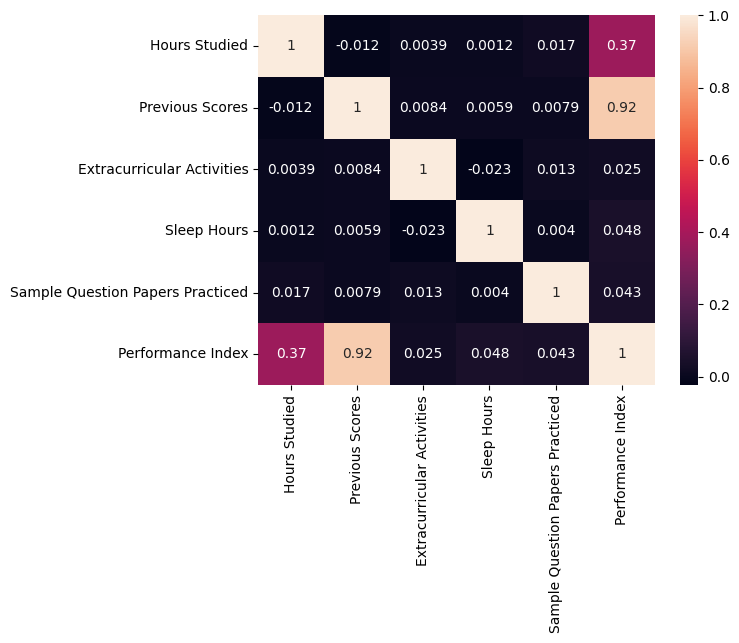

In [11]:
sns.heatmap(df.corr(),annot=True)

In [12]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

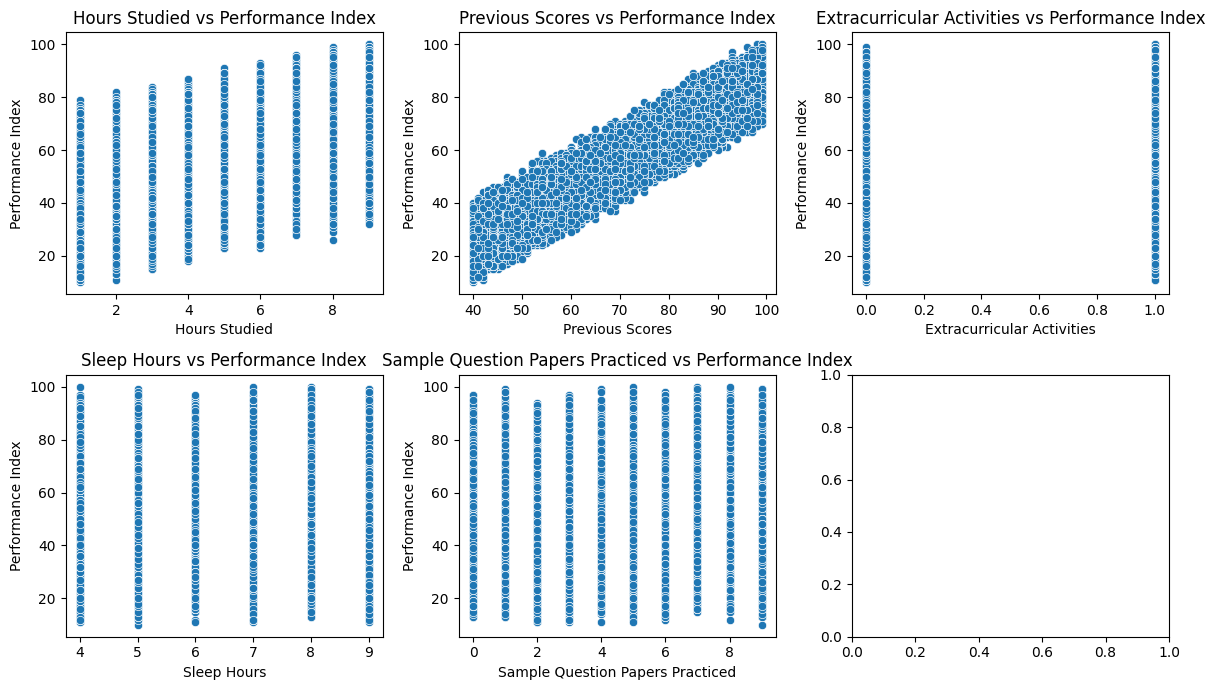

In [13]:

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12, 7))

columns = [
    'Hours Studied',
    'Previous Scores',
    'Extracurricular Activities',
    'Sleep Hours',
    'Sample Question Papers Practiced'
]

for i, column in enumerate(columns):
    row = i // 3
    col = i % 3

    ax = axes[row, col]

    sns.scatterplot(data=df, x=column, y='Performance Index', ax=ax)
    ax.set_title(f'{column} vs Performance Index')

plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X=df.drop(columns='Performance Index')
y=df['Performance Index']

In [16]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [17]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(7500, 5)
(2500, 5)
(7500,)
(2500,)


In [18]:
common=X_train.merge(X_test, how='inner')
common.shape

(304, 5)

In [19]:
# How many unique feature combinations are shared?
common_unique = X_train.merge(X_test).drop_duplicates()

print("Matching rows:", len(common))
print("Unique matching combinations:", len(common_unique))

Matching rows: 304
Unique matching combinations: 284


In [20]:
common_unique.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
0,8,56,0,9,3
1,8,87,1,5,6
2,2,68,1,4,7
3,6,82,1,7,2
4,9,42,1,9,3
5,1,92,1,4,6
6,9,58,1,5,2
8,1,47,1,5,0
9,6,89,0,8,0
10,8,48,0,9,6


In [21]:
train_check = X_train.copy()
train_check['target'] = y_train.values

test_check = X_test.copy()
test_check['target'] = y_test.values

comparison = train_check.merge(
    test_check,
    on=X_train.columns.tolist(),
    suffixes=('_train', '_test')
)

print(comparison.shape)
print("Different targets:",
      (comparison['target_train'] != comparison['target_test']).sum())

(304, 7)
Different targets: 248


In [22]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [23]:
groups = X.astype(str).agg('_'.join, axis=1)
groups

0       7_99_1_9_1
1       4_82_0_4_2
2       8_51_1_7_2
3       5_52_1_5_2
4       7_75_0_8_5
           ...    
9995    1_49_1_4_2
9996    7_64_1_8_5
9997    6_83_1_8_5
9998    9_97_1_7_0
9999    7_74_0_8_1
Length: 10000, dtype: object

In [24]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [25]:
from sklearn.linear_model import LinearRegression

In [26]:
model=LinearRegression()

In [27]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[2.86,1.02,0.56,0.48,0.19]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Hours Studied','Previous Scores','Extracurricular Activities', 'Sleep Hours','Sample Question Papers Practiced']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-34.05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [28]:
y_pred=model.predict(X_test)

In [29]:
df.tail(2)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9998,9,97,1,7,0,95.0
9999,7,74,0,8,1,64.0


In [30]:
hour=int(input("Enter the hours studied:  "))
score=int(input("Enter the previous score:  "))
activity=int(input("Does student do extracurricular?  "))
sleep=int(input("Enter the sleep hours:  "))
ques=int(input("how many sample question solved?  "))

model.predict([[hour,score,activity,sleep,ques]])

ValueError: invalid literal for int() with base 10: 'yes'

In [ ]:
from sklearn.metrics import r2_score,root_mean_squared_error,mean_absolute_error,mean_squared_error


In [ ]:
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f}")
print(f"R² Score: {r2_score(y_test, y_pred):.2f}")


MAE: 1.60
MSE: 4.13
RMSE: 2.03
R² Score: 0.99


In [ ]:
print(model.coef_)
print(model.intercept_)

[2.85593149 1.01855077 0.55807001 0.47735373 0.19063347]
-34.049980359041406


## pickling

In [ ]:
import pickle
pickle.dump(model,open('linear.pkl','wb'))

In [ ]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [ ]:
df['Hours Studied'].sort_values().unique()

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [ ]:
df['Previous Scores'].sort_values().unique()

array([40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56,
       57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73,
       74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90,
       91, 92, 93, 94, 95, 96, 97, 98, 99])

In [ ]:
df['Sleep Hours'].sort_values().unique()

array([4, 5, 6, 7, 8, 9])

In [ ]:
df['Sample Question Papers Practiced'].sort_values().unique()

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])